In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np

In [ ]:
df = pd.read_csv("f1_dnf.csv")

df.dropna(axis=1,how='any')
df.replace('\\N', pd.NA, inplace=True)


df.dropna(axis=1, inplace=True)



df.head()

,resultId,raceId,year,round,grid,positionOrder,driverRef,surname,forename,dob,...,circuitRef,circuitId,name_y,location,country,lat,lng,alt,date,target_finish
0,2460,136,2002,13,11,4,raikkonen,Räikkönen,Kimi,1979-10-17,...,hungaroring,11,McLaren,Budapest,Hungary,47.5789,19.24860,264,2002-08-18,1
1,11565,483,1981,1,23,21,watson,Watson,John,1946-05-04,...,long_beach,43,McLaren,California,USA,33.7651,-118.18900,12,1981-03-15,0
2,18661,772,1958,8,0,26,ruttman,Ruttman,Troy,1930-03-11,...,nurburgring,20,Maserati,Nürburg,Germany,50.3356,6.94750,578,1958-08-03,0
3,25121,1058,2021,8,19,16,mick_schumacher,Schumacher,Mick,1999-03-22,...,red_bull_ring,70,Haas F1 Team,Spielberg,Austria,47.2197,14.76470,678,2021-06-27,0
4,8863,383,1988,12,0,30,modena,Modena,Stefano,1963-05-12,...,monza,14,Euro Brun,Monza,Italy,45.6156,9.28111,162,1988-09-11,0


Nesse gráfico foi feita uma analise quais sao os 10 paises que mais tem corridas sediadas em seu territorio

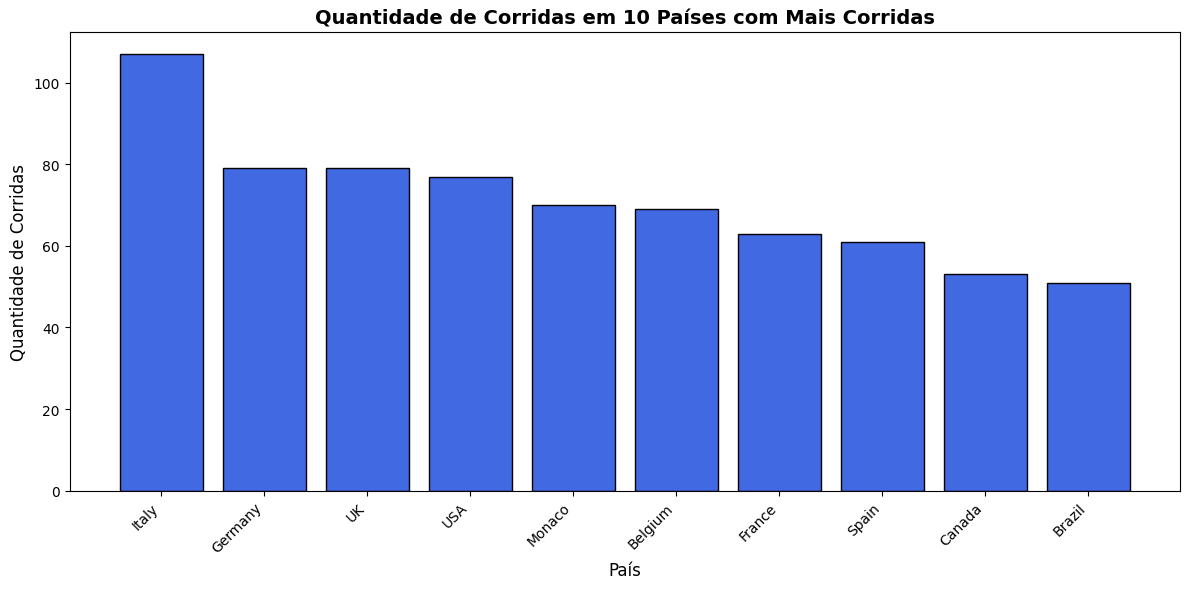

In [ ]:
#nunique garante que sera contada apenas uma vez e apos ordena os valores do maior para o menor
corridas_por_pais = df.groupby('country')['raceId'].nunique().sort_values(ascending=False)


top_10_paises = corridas_por_pais.head(10)


plt.figure(figsize=(12,6))
plt.bar(top_10_paises.index, top_10_paises.values, color='royalblue', edgecolor='black')


plt.title('Quantidade de Corridas em 10 Países com Mais Corridas', fontsize=14, fontweight='bold')
plt.xlabel('País', fontsize=12)
plt.ylabel('Quantidade de Corridas', fontsize=12)


plt.xticks(rotation=45, ha='right')


plt.tight_layout()
plt.show()

O gráfico mostra como as posições finais dos pilotos se distribuem nas corridas concluídas.
O eixo X indica as posições de chegada e o eixo Y mostra quantas vezes cada uma ocorreu.
As primeiras posições aparecem mais vezes, enquanto as últimas são menos frequentes.
Isso reflete o padrão normal das chegadas nas corridas de Fórmula 1.

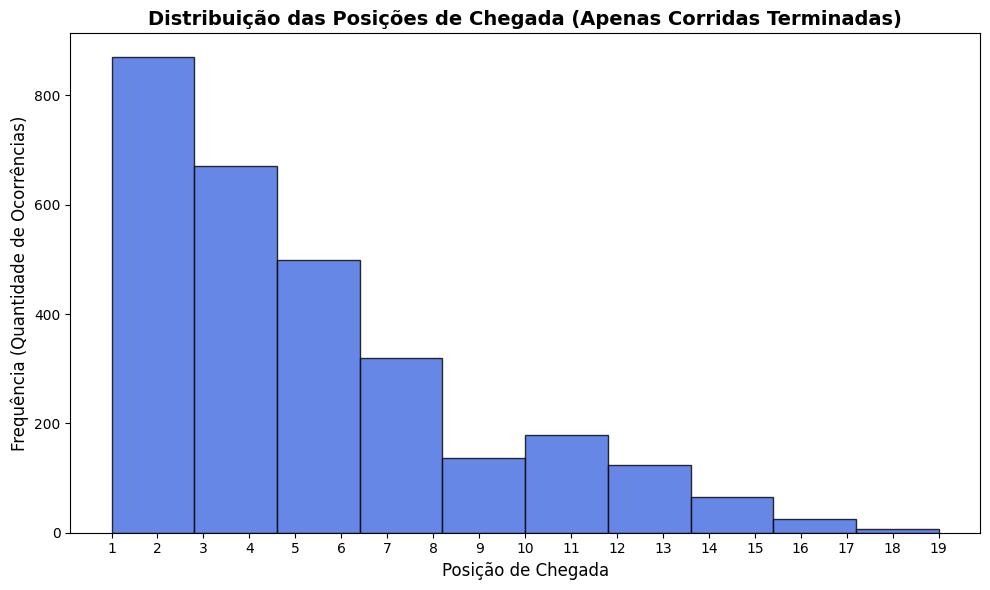

In [ ]:



df_finish = df[df['target_finish'] == 1].copy()

#garante que sejam numeros, se for texto ou vazio muda para vazio 
df_finish['positionOrder'] = pd.to_numeric(df_finish['positionOrder'], errors='coerce')





plt.figure(figsize=(10,6))
plt.hist(df_finish['positionOrder'], bins=10, color='royalblue', edgecolor='black', alpha=0.8)


plt.title('Distribuição das Posições de Chegada (Apenas Corridas Terminadas)', fontsize=14, fontweight='bold')
plt.xlabel('Posição de Chegada', fontsize=12)
plt.ylabel('Frequência (Quantidade de Ocorrências)', fontsize=12)

plt.xticks(range(1, int(df_finish['positionOrder'].max()) + 1))

plt.tight_layout()
plt.show()


